In [1]:
from google.colab import files
uploaded = files.upload()

Saving feature_names.pkl to feature_names.pkl
Saving model.pkl to model.pkl
Saving X_test.npy to X_test.npy
Saving y_test.npy to y_test.npy


In [2]:
import numpy as np
import pickle

X_test = np.load('X_test.npy')
y_test = np.load('y_test.npy')

with open('feature_names.pkl', 'rb') as f:
    feature_names = pickle.load(f)

print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)
print("Features:", feature_names)

X_test shape: (379713, 77)
y_test shape: (379713,)
Features: ['Flow Duration', 'Total Fwd Packets', 'Total Backward Packets', 'Total Length of Fwd Packets', 'Total Length of Bwd Packets', 'Fwd Packet Length Max', 'Fwd Packet Length Min', 'Fwd Packet Length Mean', 'Fwd Packet Length Std', 'Bwd Packet Length Max', 'Bwd Packet Length Min', 'Bwd Packet Length Mean', 'Bwd Packet Length Std', 'Flow Bytes/s', 'Flow Packets/s', 'Flow IAT Mean', 'Flow IAT Std', 'Flow IAT Max', 'Flow IAT Min', 'Fwd IAT Total', 'Fwd IAT Mean', 'Fwd IAT Std', 'Fwd IAT Max', 'Fwd IAT Min', 'Bwd IAT Total', 'Bwd IAT Mean', 'Bwd IAT Std', 'Bwd IAT Max', 'Bwd IAT Min', 'Fwd PSH Flags', 'Bwd PSH Flags', 'Fwd URG Flags', 'Bwd URG Flags', 'Fwd Header Length', 'Bwd Header Length', 'Fwd Packets/s', 'Bwd Packets/s', 'Min Packet Length', 'Max Packet Length', 'Packet Length Mean', 'Packet Length Std', 'Packet Length Variance', 'FIN Flag Count', 'SYN Flag Count', 'RST Flag Count', 'PSH Flag Count', 'ACK Flag Count', 'URG Flag 

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

df = pd.DataFrame(X_test, columns=feature_names)
df['Label'] = y_test
print("Dataframe ready!", df.shape)

Dataframe ready! (379713, 78)


 Class Distribution Plot

/tmp/ipykernel_1524/1037318913.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Label', data=df, palette='Set2')


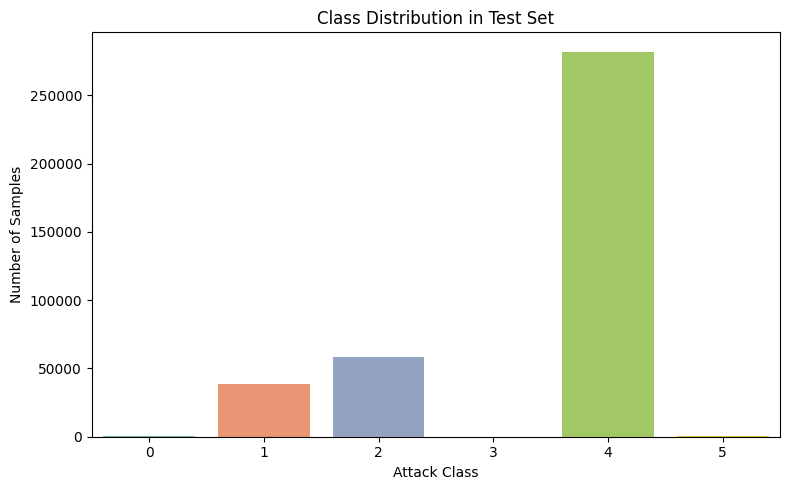

In [4]:
plt.figure(figsize=(8,5))
sns.countplot(x='Label', data=df, palette='Set2')
plt.title('Class Distribution in Test Set')
plt.xlabel('Attack Class')
plt.ylabel('Number of Samples')
plt.tight_layout()
plt.savefig('class_distribution.png')
plt.show()

Correlation Heatmap

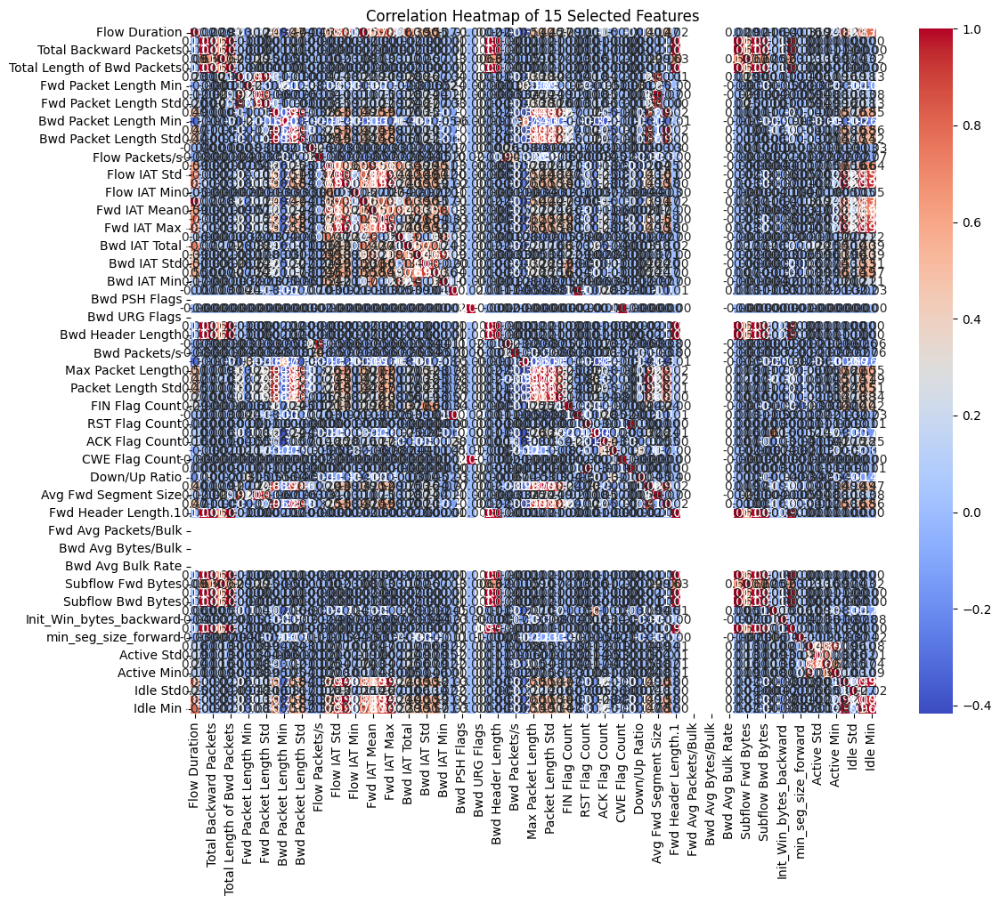

In [5]:
plt.figure(figsize=(12,10))
sns.heatmap(df[feature_names].corr(),
            annot=True, fmt='.2f',
            cmap='coolwarm', square=True)
plt.title('Correlation Heatmap of 15 Selected Features')
plt.tight_layout()
plt.savefig('correlation_heatmap.png')
plt.show()

 F1 Bar Chart

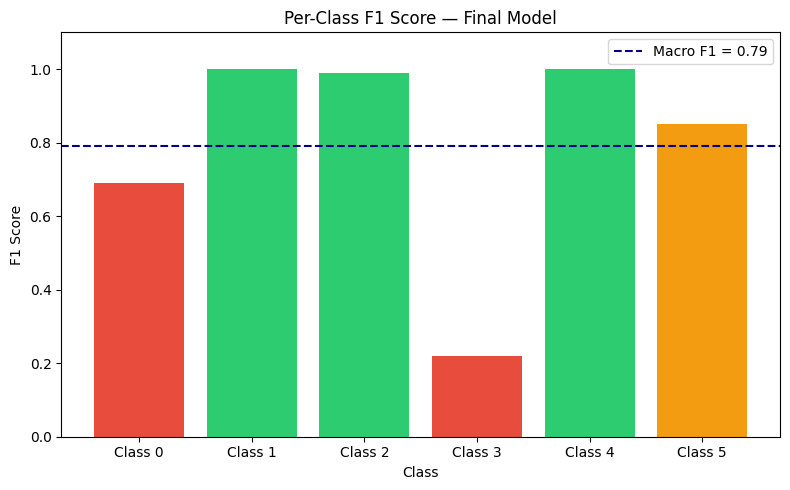

In [6]:
classes = ['Class 0','Class 1','Class 2','Class 3','Class 4','Class 5']
f1_scores = [0.69, 1.00, 0.99, 0.22, 1.00, 0.85]

plt.figure(figsize=(8,5))
plt.bar(classes, f1_scores,
        color=['#e74c3c','#2ecc71','#2ecc71','#e74c3c','#2ecc71','#f39c12'])
plt.axhline(y=0.79, color='navy', linestyle='--', label='Macro F1 = 0.79')
plt.title('Per-Class F1 Score — Final Model')
plt.xlabel('Class')
plt.ylabel('F1 Score')
plt.ylim(0, 1.1)
plt.legend()
plt.tight_layout()
plt.savefig('f1_scores.png')
plt.show()

In [9]:
from google.colab import files
uploaded = files.upload()

Saving final_features.pkl to final_features.pkl


In [10]:
with open('final_features.pkl', 'rb') as f:
    final_features = pickle.load(f)

print("Feature count:", len(final_features))
print(final_features)

Feature count: 15
['Packet Length Mean', 'Init_Win_bytes_backward', 'Fwd IAT Total', 'Init_Win_bytes_forward', 'Max Packet Length', 'Flow IAT Mean', 'Fwd Packet Length Std', 'Flow IAT Std', 'Avg Bwd Segment Size', 'Packet Length Variance', 'Fwd Packets/s', 'Flow IAT Max', 'Fwd IAT Mean', 'Packet Length Std', 'Bwd Packet Length Mean']


In [11]:
with open('model.pkl', 'rb') as f:
    model = pickle.load(f)

X_test_selected = df[final_features].values
y_pred = model.predict(X_test_selected)

print("Model loaded and y_pred generated!")
print("y_pred shape:", y_pred.shape)

Model loaded and y_pred generated!
y_pred shape: (379713,)


Confusion Matrix

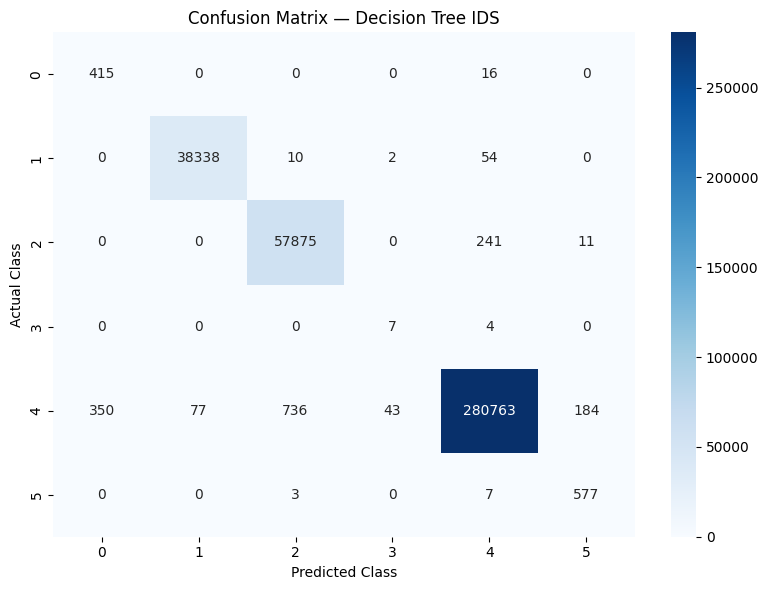

In [12]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=[0,1,2,3,4,5],
            yticklabels=[0,1,2,3,4,5])
plt.title('Confusion Matrix — Decision Tree IDS')
plt.xlabel('Predicted Class')
plt.ylabel('Actual Class')
plt.tight_layout()
plt.savefig('confusion_matrix.png', dpi=150)
plt.show()

SHAP Beeswarm

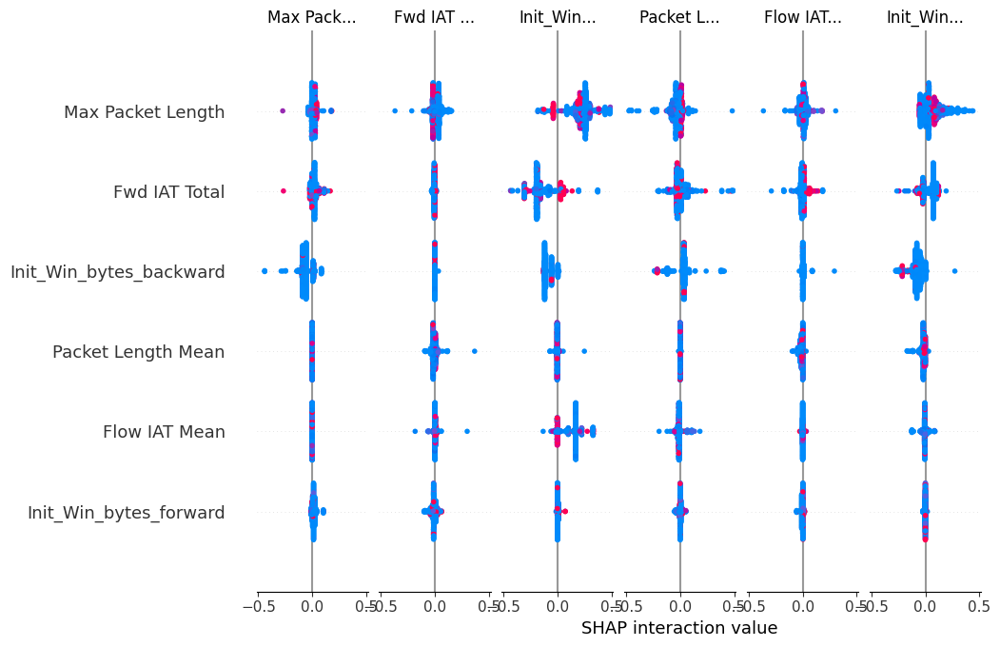

In [13]:
!pip install shap -q

import shap

explainer = shap.TreeExplainer(model)
sample = X_test_selected[:500]
shap_values = explainer.shap_values(sample)

shap.summary_plot(shap_values, sample, feature_names=final_features)

LIME

In [15]:
!pip install lime -q

from lime.lime_tabular import LimeTabularExplainer

explainer_lime = LimeTabularExplainer(
    X_test_selected,
    feature_names=final_features,
    class_names=['0','1','2','3','4','5'],
    mode='classification'
)

for target_class in range(6):
    idxs = np.where(y_test == target_class)[0]
    if len(idxs) == 0:
        continue
    exp = explainer_lime.explain_instance(
        X_test_selected[idxs[0]],
        model.predict_proba,
        num_features=10
    )
    print(f"\nClass {target_class} explanation:")
    exp.show_in_notebook()

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 275.7/275.7 kB 8.1 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done

Class 0 explanation:



Class 1 explanation:



Class 2 explanation:



Class 3 explanation:



Class 4 explanation:



Class 5 explanation:
